# 02 — Sentinel-2 snow persistence

**Kok Zhailau ski terrain analytics — an independent open-data case study**
Dias Irishev · Geo & Weather Data Scientist, Almaty

Four complete snow seasons of Sentinel-2 L2A over MGRS tile **43TFH**, reduced to
a per-pixel snow-detection frequency, an observation-coverage layer, and bracketed
snow-disappearance intervals.

**What the satellite measures.** A frequency here is *the share of usable satellite
dates on which a pixel looked like snow* — nothing more. It is not ski days, not
snow depth, and not a snowmaking cost. Those need ground measurement.

In [1]:
import os
os.environ["KZ_AREA"] = "superski"   # the current study area, derived from the
#                                      operator's general plan - see notebook 06

import json
import sys
from datetime import date
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from config import (CURRENT_SEASON, INTERIM, MAX_CLOUD_PCT, MGRS_TILE,
                    MIN_SEASONS_MULTIYEAR, MIN_VALID_OBS, NDSI_THRESHOLD,
                    NIR_THRESHOLD, OUT_TAB, OUT_TIF, SEASONS, SPRING_WINDOW,
                    STAC_COLLECTION, STAC_URL)
from dem import write_geotiff
from grids import S2_GRID
from pipeline_snow import (coverage_table, current_season_days, historical_days,
                           load_days)
from snow import day_to_date, meltout_interval, select_days, snow_frequency
from viz import map_panel, save

pd.set_option("display.width", 150)
RUN_DATE = date.today().isoformat()
print(f"run date        : {RUN_DATE}")
print(f"STAC endpoint   : {STAC_URL}  collection '{STAC_COLLECTION}'")
print(f"tile / filter   : {MGRS_TILE}, metadata cloud cover < {MAX_CLOUD_PCT}%")
print(f"snow rule       : NDSI > {NDSI_THRESHOLD} AND B08 > {NIR_THRESHOLD} (reflectance)")
print(f"grid            : {S2_GRID.shape[0]} × {S2_GRID.shape[1]} @ 20 m, {S2_GRID.crs}")

run date        : 2026-11-24
STAC endpoint   : https://earth-search.aws.element84.com/v1  collection 'sentinel-2-l2a'
tile / filter   : 43TFH, metadata cloud cover < 15.0%
snow rule       : NDSI > 0.4 AND B08 > 0.11 (reflectance)
grid            : 400 × 437 @ 20 m, EPSG:32643


## 1. Scenes and the manifest

Only the AOI window of each COG is read, so a season costs megabytes rather than
gigabytes. Windows are cached outside the release folder, which makes the download
resumable after a failure.

In [2]:
days, manifest, failed = load_days(verbose=True)
manifest.to_csv(OUT_TAB / "scene_manifest.csv", index=False)
print(f"\nscenes returned : {len(manifest)}")
print(f"unique dates    : {len(days)}  (same-date scenes merged)")
print(f"download errors : {len(failed)}")
if failed:
    print(pd.DataFrame(failed).to_string(index=False))

per_season = (manifest.assign(season=lambda d: d["date"].map(
    lambda x: next((k for k, (s, e) in SEASONS.items() if s <= x <= e),
                   CURRENT_SEASON[0])))
    .groupby("season")
    .agg(scenes=("scene_id", "size"), dates=("date", "nunique"),
         first=("date", "min"), last=("date", "max"),
         mean_cloud_pct=("cloud_cover_pct", "mean"),
         mean_valid_fraction=("valid_fraction", "mean"))
    .round(3).reset_index())
per_season.to_csv(OUT_TAB / "scenes_per_season.csv", index=False)
print("\n" + per_season.to_string(index=False))
print(f"\nradiometric scale/offset in use: "
      f"{sorted(manifest['scale'].unique())} / {sorted(manifest['offset'].unique())}")
print(f"processing baselines: {sorted(manifest['processing_baseline'].dropna().unique())}")

  115 scenes: 115 cached, 0 to download



scenes returned : 115
unique dates    : 112  (same-date scenes merged)
download errors : 0

 season  scenes  dates      first       last  mean_cloud_pct  mean_valid_fraction
2022_23      30     30 2022-11-01 2023-04-27           7.895                0.613
2023_24      28     27 2023-11-01 2024-04-21           6.908                0.647
2024_25      25     25 2024-11-10 2025-04-29           6.347                0.623
2025_26      31     29 2025-11-02 2026-04-29           7.290                0.619
2026_27       1      1 2026-11-07 2026-11-07           0.140                0.480

radiometric scale/offset in use: [np.float64(0.0001)] / [np.float64(-0.1)]
processing baselines: ['04.00', '05.09', '05.10', '05.11', '05.12', '05.13']


Every scene in this run came from Element 84 Earth Search. No fallback to another
archive was needed, so there is no collection change to declare.

In [3]:
hist = historical_days(days)
cur = current_season_days(days)
print(f"historical observation dates (4 complete seasons): {len(hist)}")
print(f"current season {CURRENT_SEASON[0].replace('_','/')} dates so far: {len(cur)}")

historical observation dates (4 complete seasons): 111
current season 2026/27 dates so far: 1


## 2. Why these thresholds

NDSI > 0.40 with a NIR floor is the standard Sentinel-2 snow test: NDSI alone
also fires on water and some cloud, and the B08 floor removes most of that. Below,
the rule is re-run across a grid of thresholds on six March–April scenes to show
how much the answer actually moves.

In [4]:
from s2 import fetch_scene_raw

recs = json.load(open(INTERIM / "stac_records.json"))
probe = [r for r in recs["2022_23"] if "2023-03" in r["date"] or "2023-04" in r["date"]][:6]
rows = []
for r in probe:
    raw = fetch_scene_raw(r)
    v = raw["valid"]
    for nd in (0.30, 0.40, 0.50):
        for nir in (0.07, 0.11, 0.15):
            sn = (raw["ndsi"] > nd) & (raw["nir"] > nir) & v & (~raw["never_snow"])
            rows.append({"date": raw["date"], "ndsi_thr": nd, "nir_thr": nir,
                         "snow_fraction_of_valid": float(sn.sum() / max(v.sum(), 1))})
sens = (pd.DataFrame(rows).groupby(["ndsi_thr", "nir_thr"])["snow_fraction_of_valid"]
        .mean().mul(100).round(1).unstack())
sens.to_csv(OUT_TAB / "ndsi_threshold_sensitivity.csv")
print("Mean snow fraction of valid pixels (%), 6 scenes in March–April 2023:")
print(sens.to_string())
base = sens.loc[NDSI_THRESHOLD, NIR_THRESHOLD]
print(f"\nchosen rule (NDSI>{NDSI_THRESHOLD}, B08>{NIR_THRESHOLD}): {base:.1f}%")
print(f"spread across the whole grid: {sens.values.min():.1f}% – {sens.values.max():.1f}%")

Mean snow fraction of valid pixels (%), 6 scenes in March–April 2023:
nir_thr   0.07  0.11  0.15
ndsi_thr                  
0.3       74.6  72.9  70.3
0.4       71.9  70.2  67.7
0.5       68.5  66.8  64.4

chosen rule (NDSI>0.4, B08>0.11): 70.2%
spread across the whole grid: 64.4% – 74.6%


### Agreement with the Sen2Cor snow class

The SCL snow class (11) is produced independently by the L2A processor; the two
should broadly agree without being identical.

scene-level correlation NDSI rule vs SCL class 11: r = 0.970  (n = 115)
mean difference (NDSI rule − SCL): -0.117


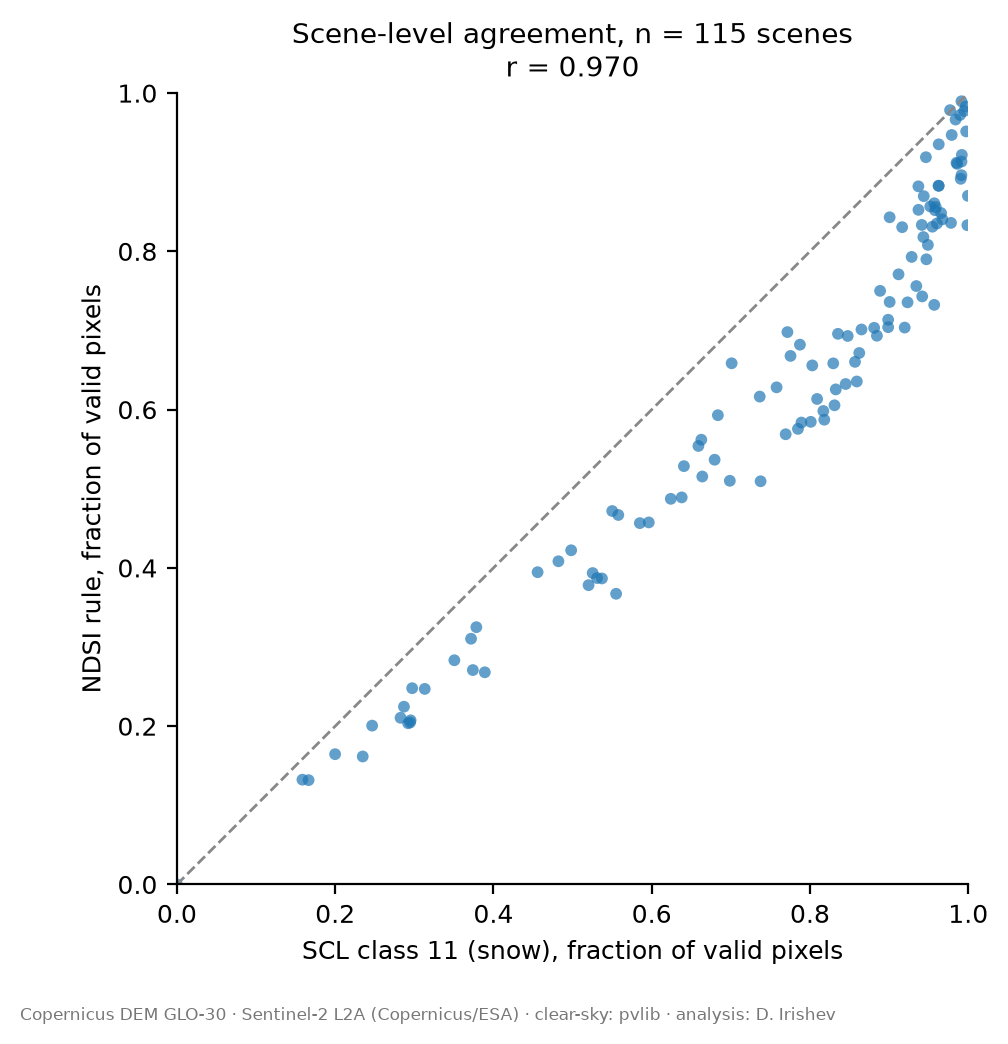

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/02_ndsi_vs_scl_agreement.png')

In [5]:
agree = manifest[["date", "snow_fraction_of_valid", "scl_snow_fraction_of_valid"]].dropna()
r = np.corrcoef(agree["snow_fraction_of_valid"], agree["scl_snow_fraction_of_valid"])[0, 1]
bias = (agree["snow_fraction_of_valid"] - agree["scl_snow_fraction_of_valid"]).mean()
print(f"scene-level correlation NDSI rule vs SCL class 11: r = {r:.3f}  (n = {len(agree)})")
print(f"mean difference (NDSI rule − SCL): {bias:+.3f}")

fig, ax = plt.subplots(figsize=(5.2, 5.0))
ax.scatter(agree["scl_snow_fraction_of_valid"], agree["snow_fraction_of_valid"],
           s=18, alpha=0.7, edgecolor="none")
ax.plot([0, 1], [0, 1], color="#888", lw=1, ls="--")
ax.set_xlabel("SCL class 11 (snow), fraction of valid pixels")
ax.set_ylabel("NDSI rule, fraction of valid pixels")
ax.set_title(f"Scene-level agreement, n = {len(agree)} scenes\nr = {r:.3f}")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
fig.tight_layout()
save(fig, "02_ndsi_vs_scl_agreement.png")

## 3. Coverage

A frequency is only published where a pixel has at least **4** usable observations
in the period. Cast shadow, cloud shadow, cloud and cirrus are all removed before
counting, so shaded north slopes in midwinter lose observations exactly where the
snow signal matters most — a bias worth stating rather than hiding.

In [6]:
labels = {f"season {s.replace('_','/')}": select_days(hist, seasons=[s]) for s in SEASONS}
labels["Mar–Apr 2023 (pilot comparison)"] = select_days(hist, start="2023-03-01", end="2023-04-30")
labels[f"spring window {SPRING_WINDOW[0]}→{SPRING_WINDOW[1]}, 4 seasons"] = select_days(
    hist, month_day_window=SPRING_WINDOW)
labels["all four seasons"] = hist
cov = coverage_table(labels)
cov.to_csv(OUT_TAB / "coverage_by_period.csv", index=False)
print(cov.to_string(index=False))

                              period  n_dates  n_seasons  median_valid_obs_per_pixel  coverage_min4 first_date  last_date
                      season 2022/23       30          1                          15         0.9182 2022-11-01 2023-04-27
                      season 2023/24       27          1                          15         0.9282 2023-11-01 2024-04-21
                      season 2024/25       25          1                          14         0.9046 2024-11-10 2025-04-29
                      season 2025/26       29          1                          16         0.9640 2025-11-02 2026-04-29
     Mar–Apr 2023 (pilot comparison)       13          1                          11         0.8610 2023-03-01 2023-04-27
spring window 03-11→04-20, 4 seasons       31          4                          28         0.9743 2023-03-11 2026-04-14
                    all four seasons      111          4                          61         0.9927 2022-11-01 2026-04-29


## 4. Snow detection frequency

Each season contributes equally to a multi-season mean, so a season with many clear
dates cannot outvote a cloudy one. The four-season map additionally requires at
least **3** seasons of support per pixel.

In [7]:
season_freq = {}
for s in SEASONS:
    sel = select_days(hist, seasons=[s])
    season_freq[s] = snow_frequency(sel, min_valid=MIN_VALID_OBS)
    r_ = season_freq[s]
    print(f"{s.replace('_','/')}: {r_['n_dates']:2d} dates, coverage {r_['coverage']*100:5.1f}%, "
          f"median frequency {np.nanmedian(r_['frequency']):.3f}")

four = snow_frequency(hist, min_valid=MIN_VALID_OBS, min_seasons=MIN_SEASONS_MULTIYEAR)
print(f"\nfour-season map: {four['n_dates']} dates over {len(four['seasons'])} seasons, "
      f"coverage {four['coverage']*100:.1f}% "
      f"(≥{MIN_VALID_OBS} obs and ≥{MIN_SEASONS_MULTIYEAR} seasons)")
print(f"median frequency {np.nanmedian(four['frequency']):.3f}")

2022/23: 30 dates, coverage  91.8%, median frequency 0.750
2023/24: 27 dates, coverage  92.8%, median frequency 0.833
2024/25: 25 dates, coverage  90.5%, median frequency 0.800
2025/26: 29 dates, coverage  96.4%, median frequency 0.773

four-season map: 111 dates over 4 seasons, coverage 99.0% (≥4 obs and ≥3 seasons)
median frequency 0.752


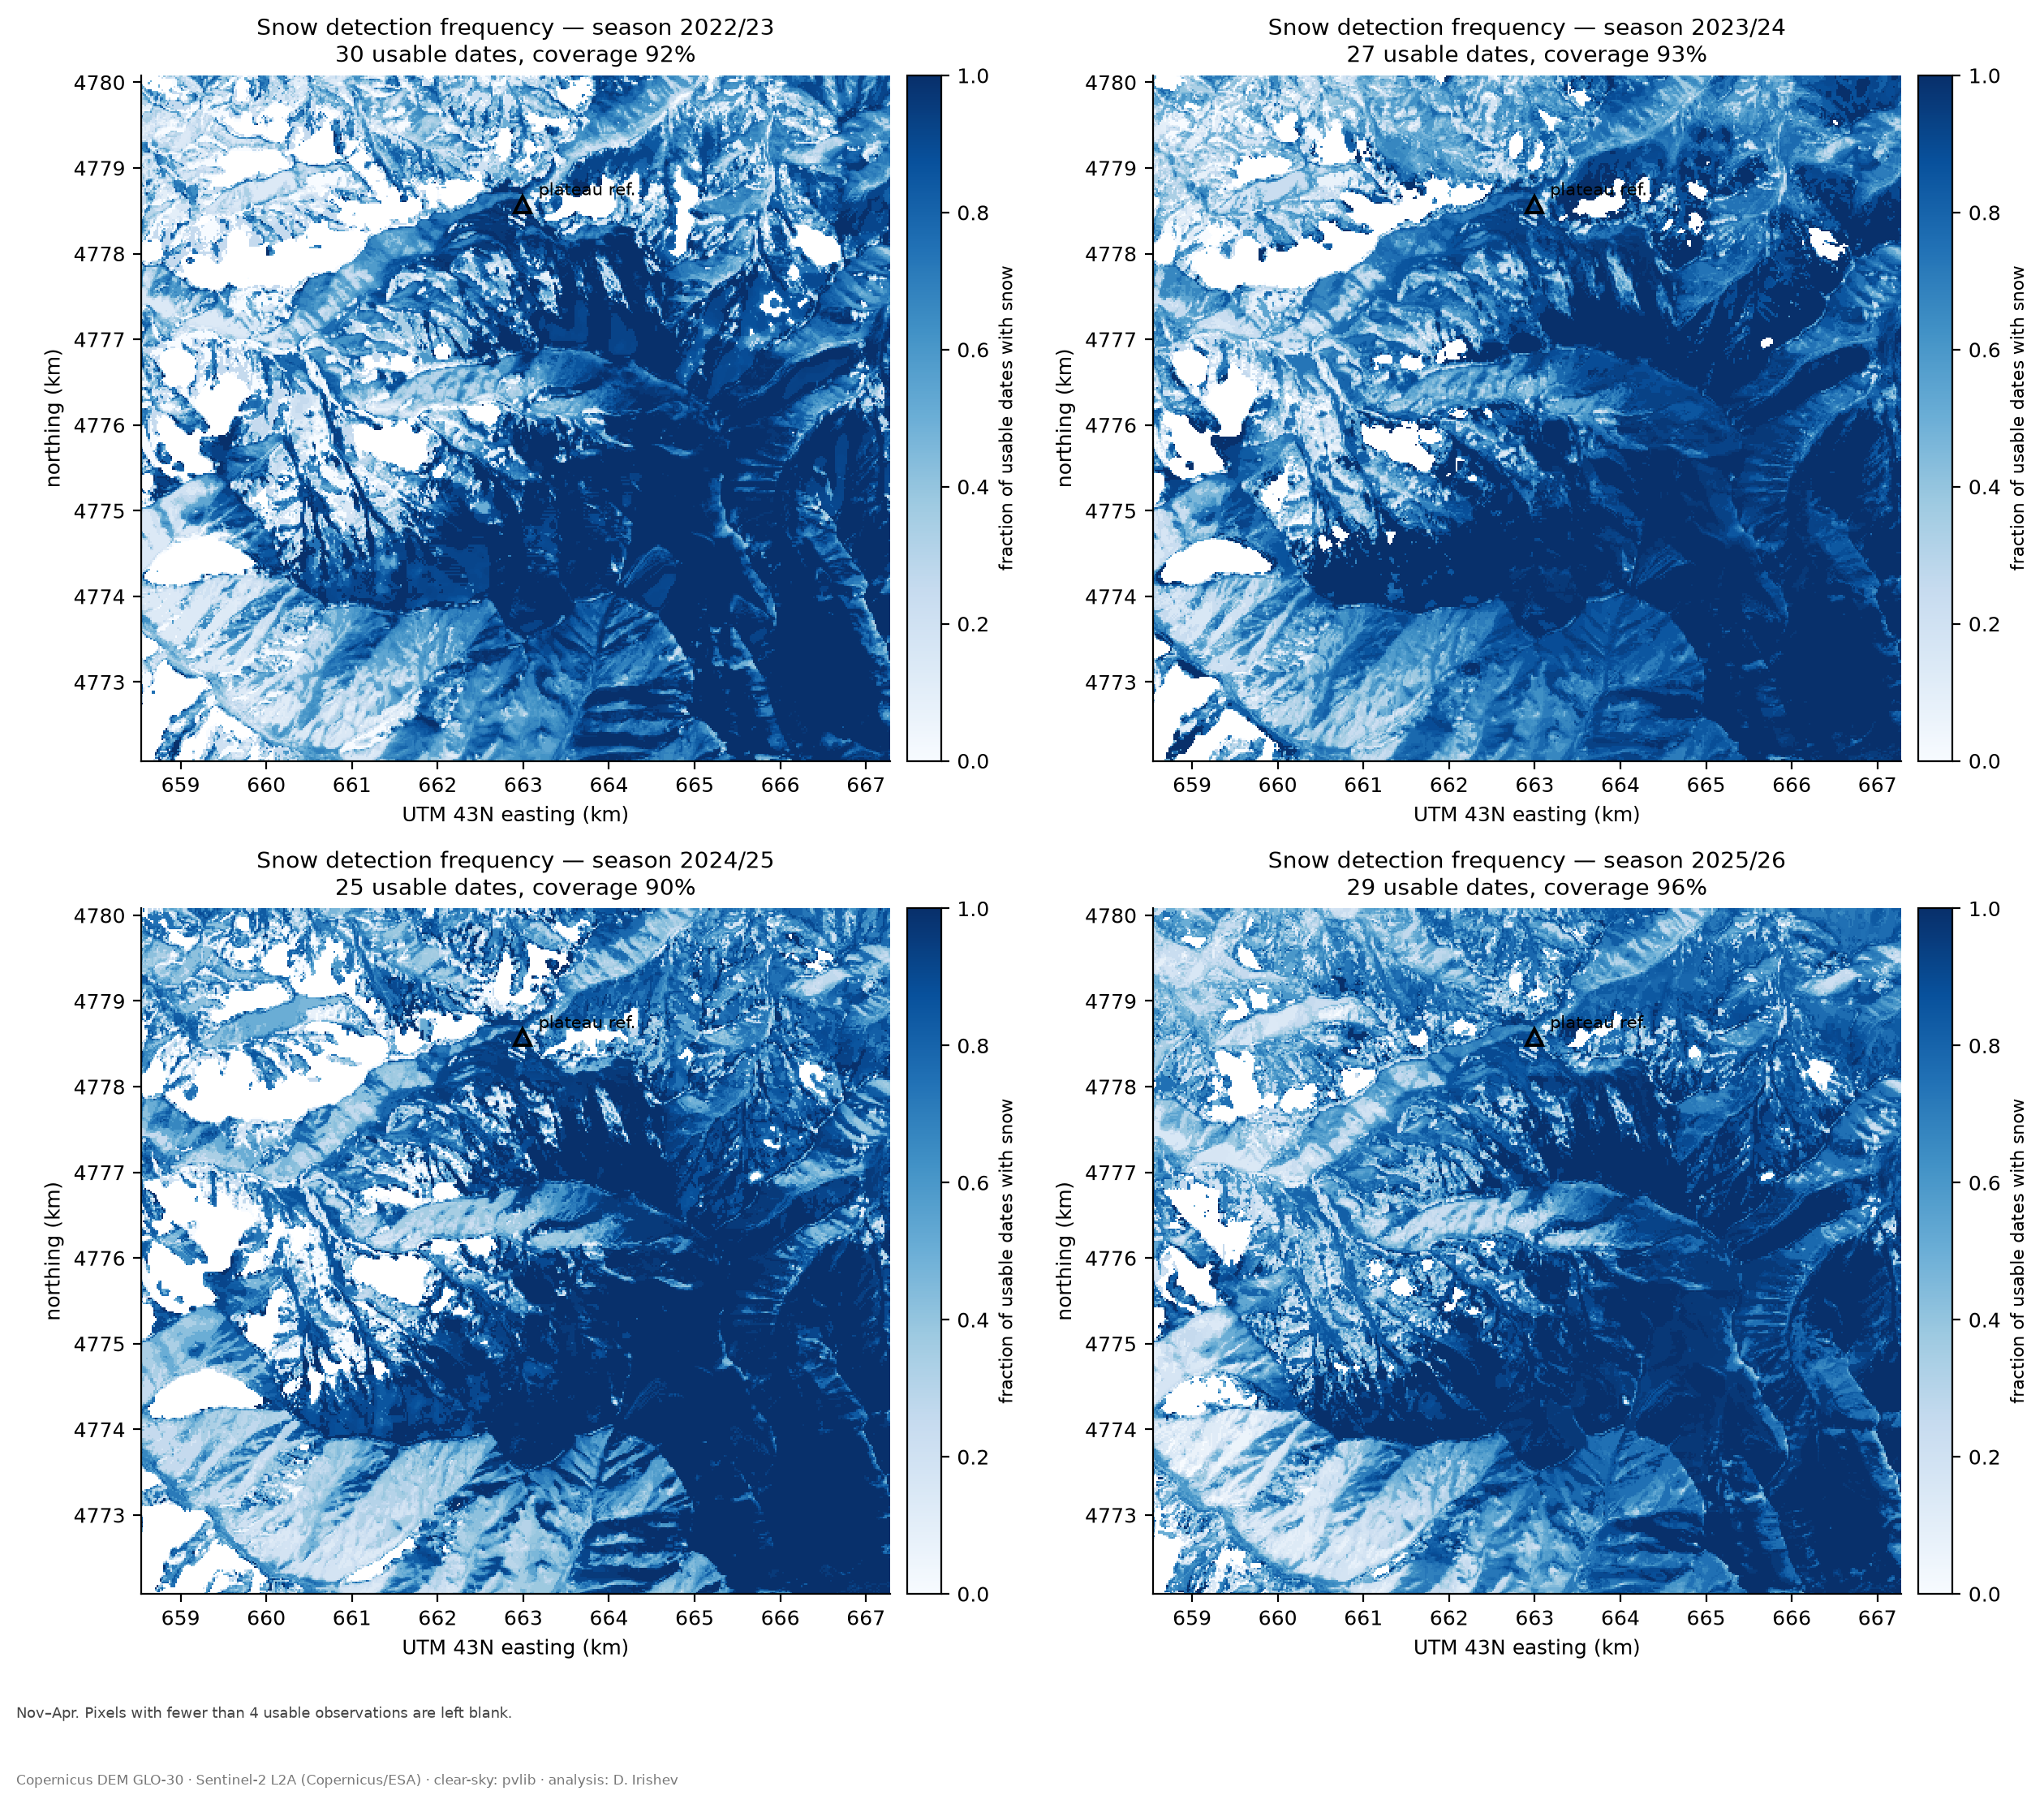

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/02_snow_frequency_by_season.png')

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12.6, 10.4))
for ax, s in zip(axes.ravel(), SEASONS):
    r_ = season_freq[s]
    map_panel(ax, r_["frequency"], S2_GRID, "Blues", 0, 1,
              title=f"Snow detection frequency — season {s.replace('_','/')}\n"
                    f"{r_['n_dates']} usable dates, coverage {r_['coverage']*100:.0f}%",
              cbar_label="fraction of usable dates with snow", shade=0)
fig.tight_layout()
save(fig, "02_snow_frequency_by_season.png",
     f"Nov–Apr. Pixels with fewer than {MIN_VALID_OBS} usable observations are left blank.")

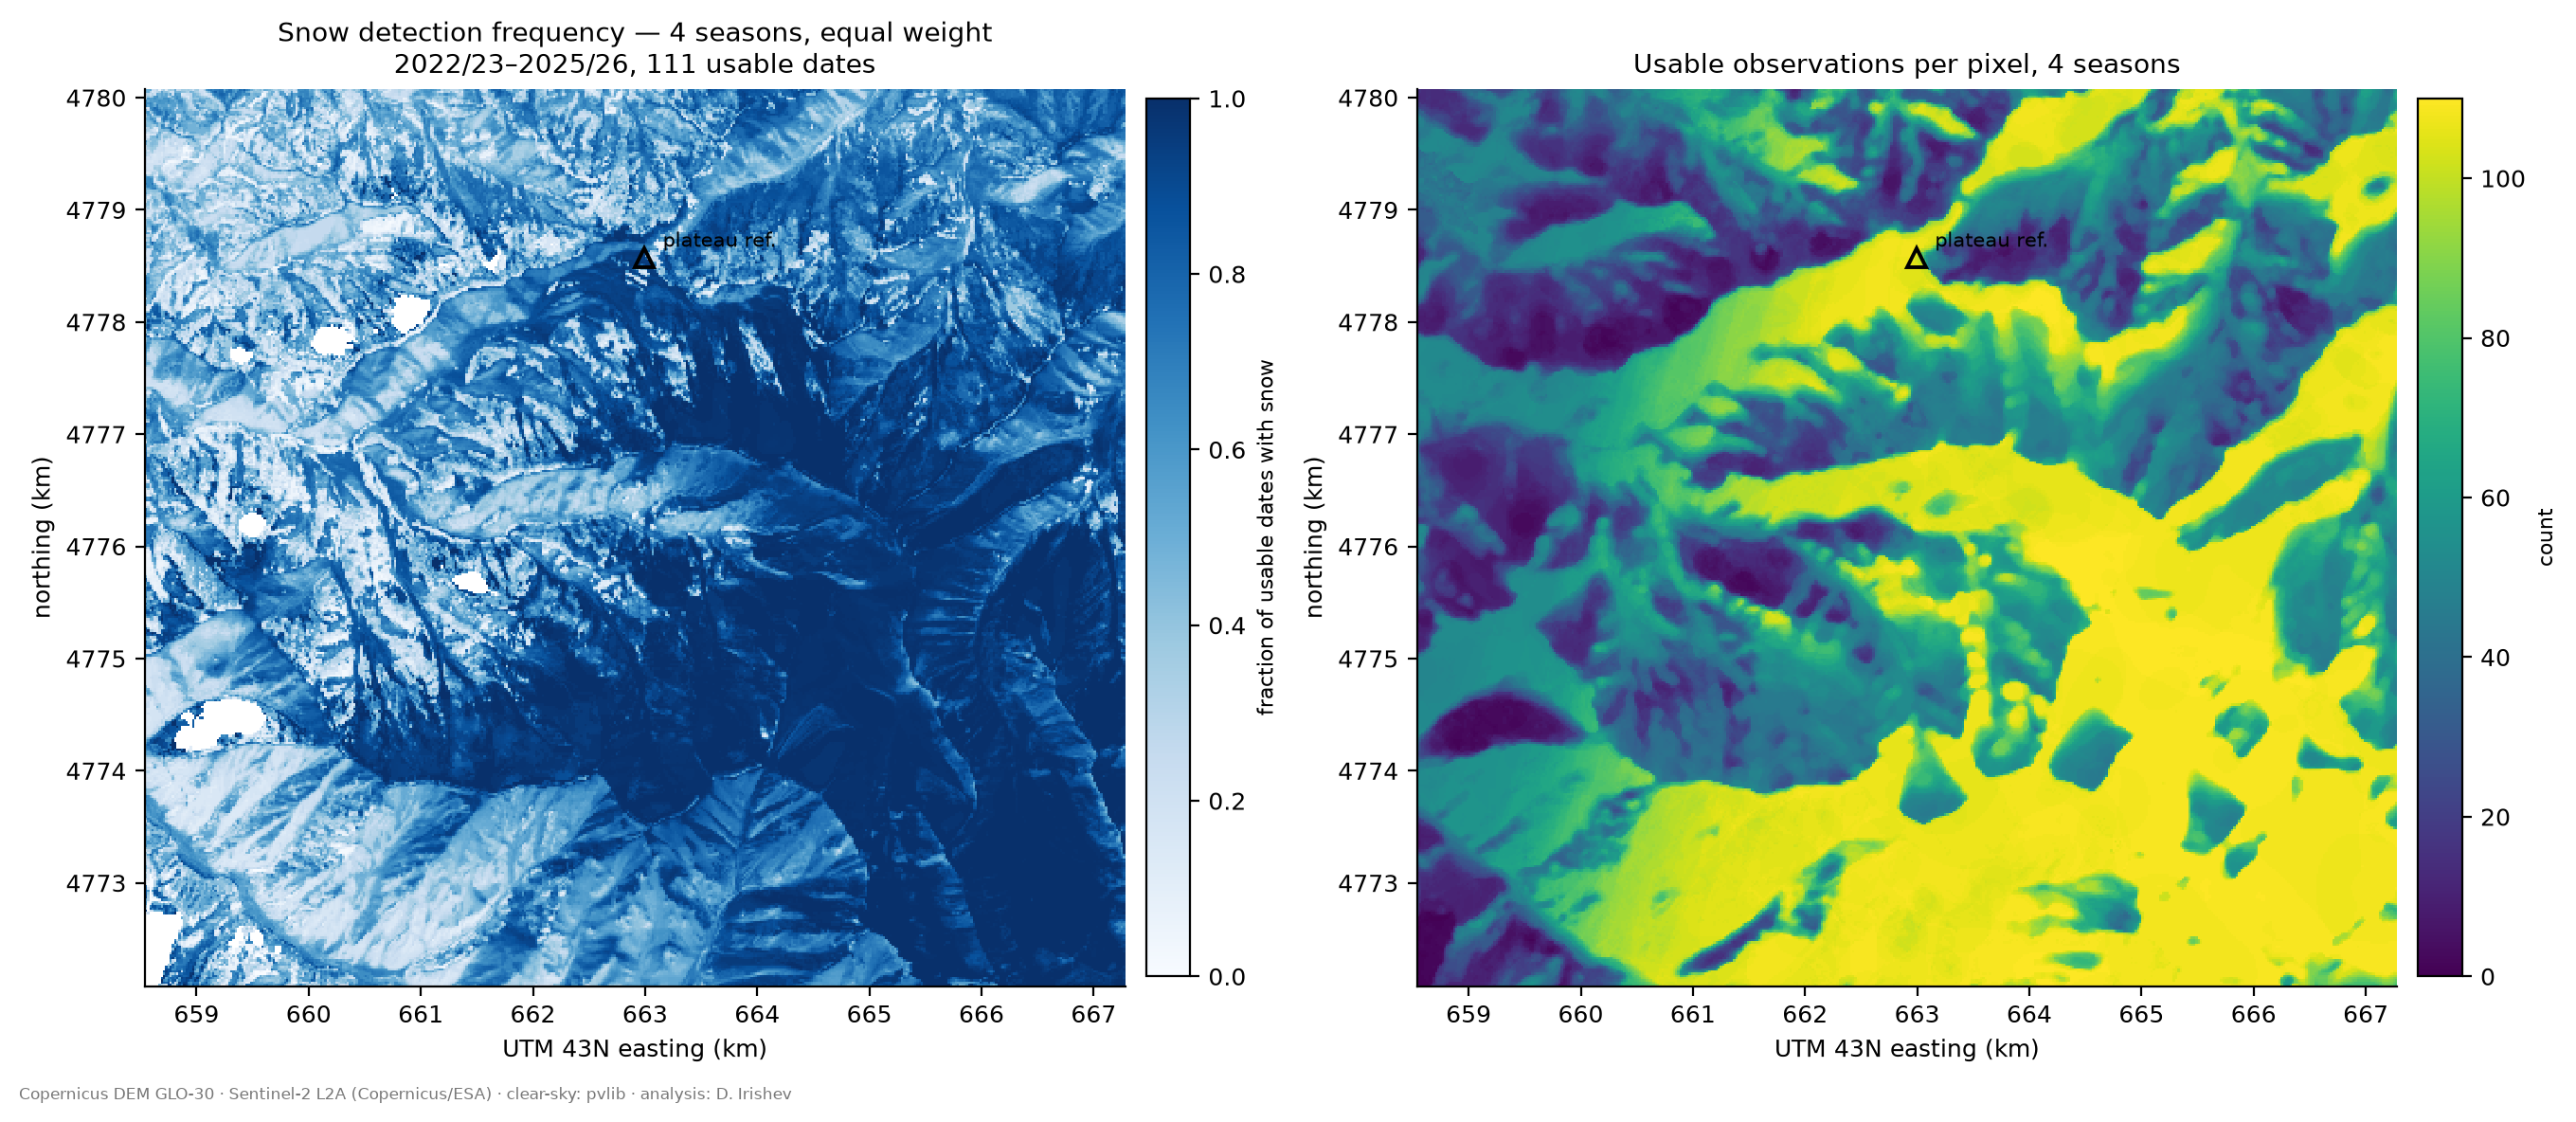

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/02_snow_frequency_4season.png')

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.6))
map_panel(axes[0], four["frequency"], S2_GRID, "Blues", 0, 1,
          title=f"Snow detection frequency — 4 seasons, equal weight\n"
                f"2022/23–2025/26, {four['n_dates']} usable dates",
          cbar_label="fraction of usable dates with snow", shade=0)
map_panel(axes[1], four["n_valid"].astype("float32"), S2_GRID, "viridis",
          title="Usable observations per pixel, 4 seasons",
          cbar_label="count", shade=0)
fig.tight_layout()
save(fig, "02_snow_frequency_4season.png")

## 5. Snow disappearance intervals

The satellite brackets rather than dates the melt-out: the last date a pixel was
seen with snow, and the first usable snow-free date after it. The midpoint is
reported with the width of the bracket, and pixels without both bounds stay empty.

In [10]:
melt_rows, melt = [], {}
for s in SEASONS:
    m = meltout_interval(hist, s)
    melt[s] = m
    ok = np.isfinite(m["meltout_mid_day"])
    melt_rows.append({
        "season": s.replace("_", "/"), "n_dates": m["n_dates"],
        "estimated_fraction": round(m["estimated_fraction"], 3),
        "median_meltout_date": day_to_date(np.nanmedian(m["meltout_mid_day"]), m["origin"]),
        "p25_meltout_date": day_to_date(np.nanpercentile(m["meltout_mid_day"][ok], 25), m["origin"]),
        "p75_meltout_date": day_to_date(np.nanpercentile(m["meltout_mid_day"][ok], 75), m["origin"]),
        "median_bracket_width_days": round(float(np.nanmedian(m["interval_width_days"])), 1),
    })
melt_df = pd.DataFrame(melt_rows)
melt_df.to_csv(OUT_TAB / "meltout_by_season.csv", index=False)
print(melt_df.to_string(index=False))

 season  n_dates  estimated_fraction median_meltout_date p25_meltout_date p75_meltout_date  median_bracket_width_days
2022/23       30               0.488          2023-03-08       2023-03-03       2023-04-03                        5.0
2023/24       27               0.370          2024-04-03       2024-03-21       2024-04-11                       10.0
2024/25       25               0.566          2025-04-08       2025-03-15       2025-04-08                        8.0
2025/26       29               0.658          2026-04-01       2026-03-17       2026-04-12                       12.0


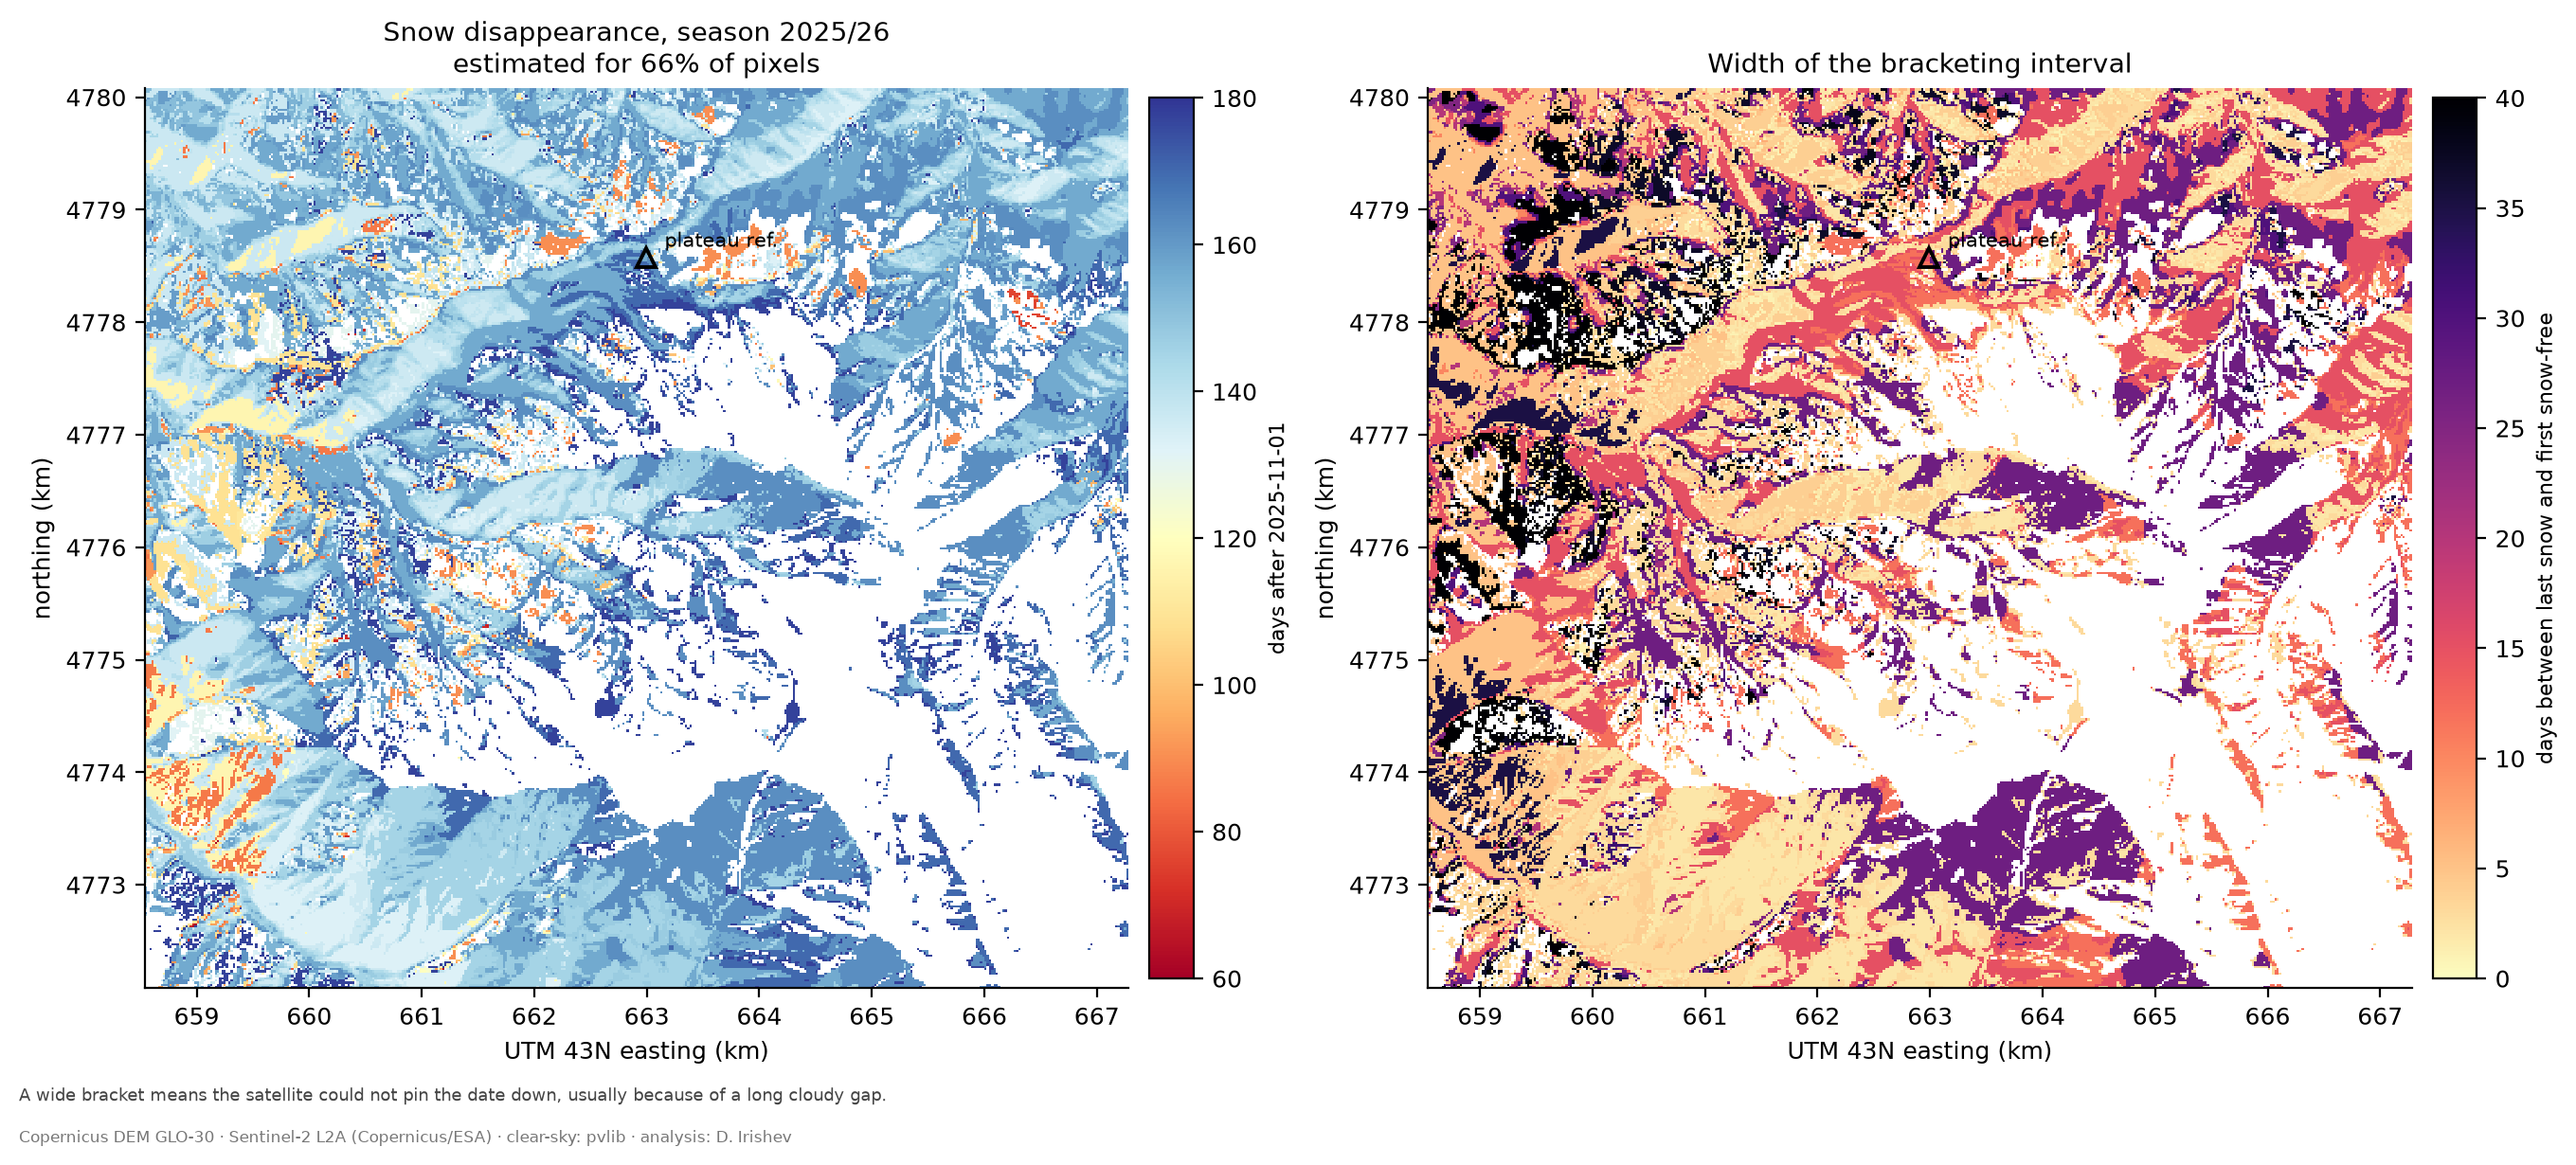

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/02_meltout_2025_26.png')

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.6))
m = melt["2025_26"]
map_panel(axes[0], m["meltout_mid_day"], S2_GRID, "RdYlBu", 60, 180,
          title=f"Snow disappearance, season 2025/26\n"
                f"estimated for {m['estimated_fraction']*100:.0f}% of pixels",
          cbar_label=f"days after {m['origin']}", shade=0)
map_panel(axes[1], m["interval_width_days"], S2_GRID, "magma_r", 0, 40,
          title="Width of the bracketing interval",
          cbar_label="days between last snow and first snow-free", shade=0)
fig.tight_layout()
save(fig, "02_meltout_2025_26.png",
     "A wide bracket means the satellite could not pin the date down, usually because "
     "of a long cloudy gap.")

## 6. The freshest scene available on the run date

query_date acquisition_date                scene_ids  metadata_cloud_cover_pct  valid_pixel_fraction  snow_fraction_of_valid    platform
2026-11-24       2026-11-07 S2B_43TFH_20261107_0_L2A                      0.14                0.3786                  0.4215 sentinel-2b


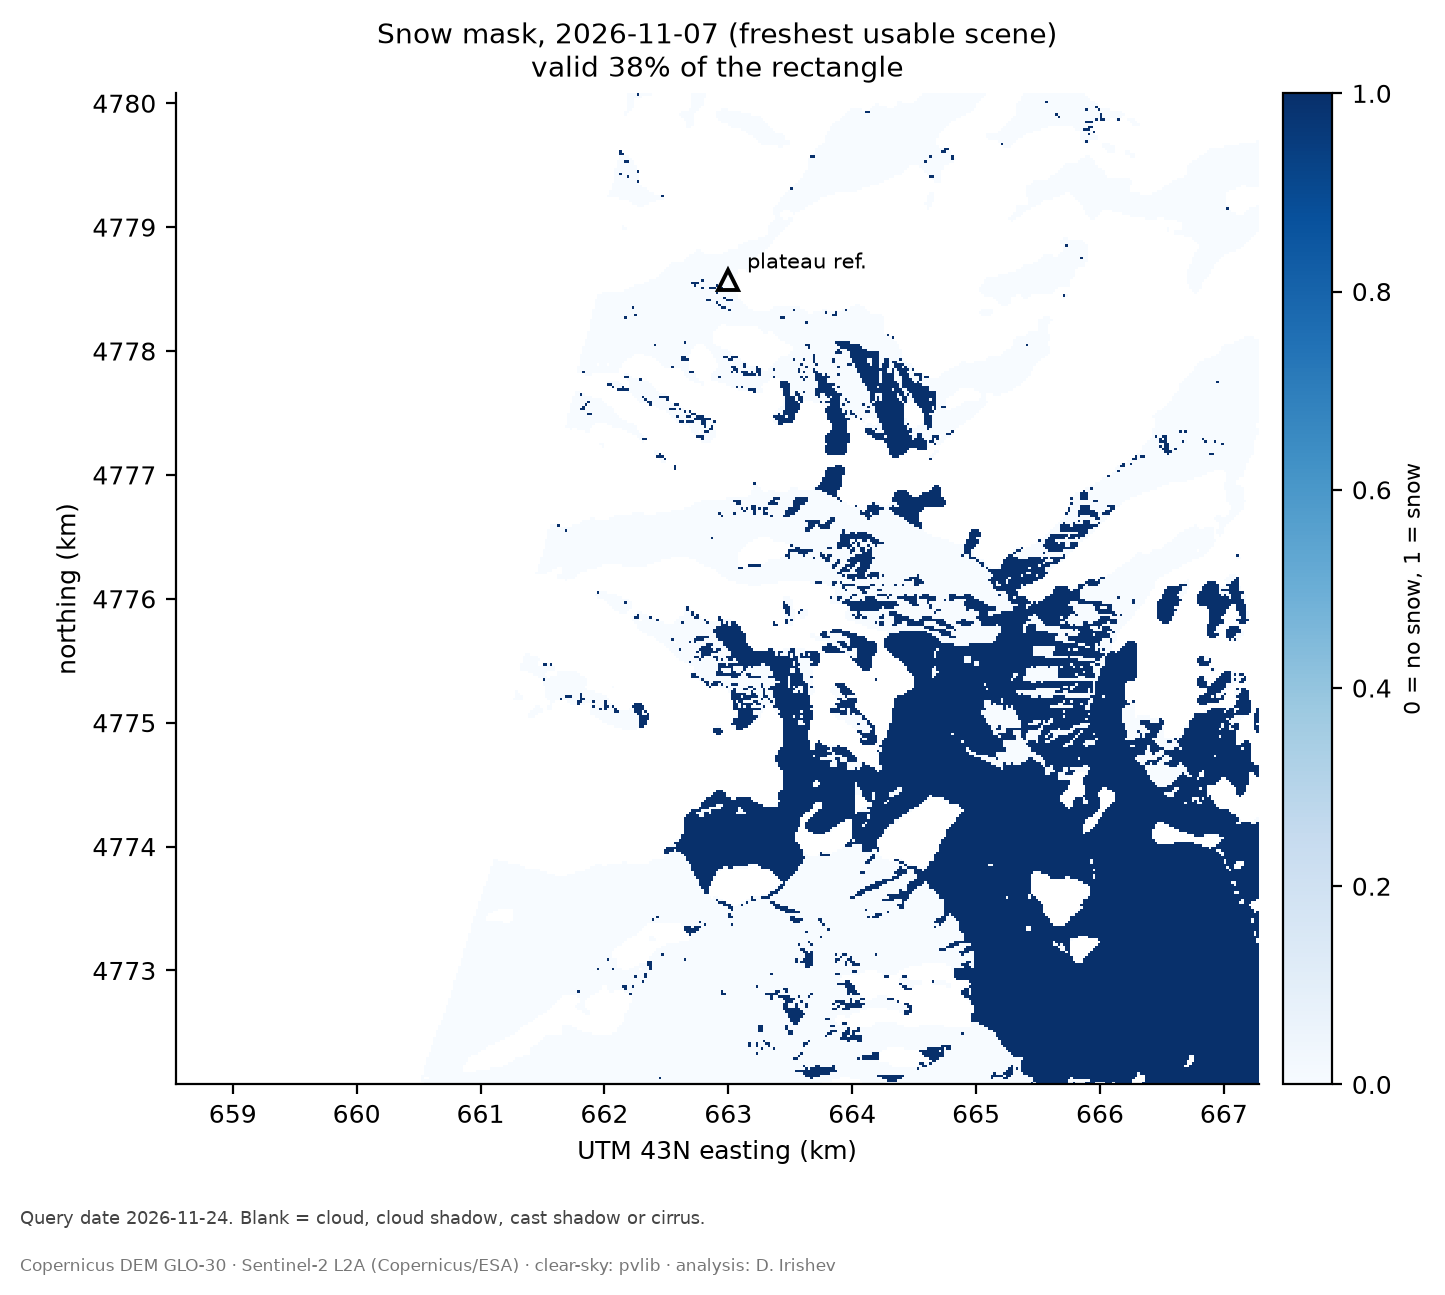

In [12]:
fresh_rows = []
if cur:
    for rec in cur:
        meta = manifest[manifest["date"] == rec["date"]].iloc[0]
        valid = rec["valid"]
        snow = rec["snow"] & valid
        fresh_rows.append({
            "query_date": RUN_DATE, "acquisition_date": rec["date"],
            "scene_ids": ", ".join(rec["scene_ids"]),
            "metadata_cloud_cover_pct": meta["cloud_cover_pct"],
            "valid_pixel_fraction": round(float(valid.mean()), 4),
            "snow_fraction_of_valid": round(float(snow.sum() / max(valid.sum(), 1)), 4),
            "platform": meta["platform"],
        })
    fresh = pd.DataFrame(fresh_rows)
    fresh.to_csv(OUT_TAB / "fresh_scene_report.csv", index=False)
    print(fresh.to_string(index=False))
    latest = cur[-1]
    fig, ax = plt.subplots(figsize=(7.2, 6.0))
    disp = np.where(latest["valid"], latest["snow"].astype("float32"), np.nan)
    map_panel(ax, disp, S2_GRID, "Blues", 0, 1,
              title=f"Snow mask, {latest['date']} (freshest usable scene)\n"
                    f"valid {latest['valid'].mean()*100:.0f}% of the rectangle",
              cbar_label="0 = no snow, 1 = snow", shade=0)
    fig.tight_layout()
    save(fig, "02_fresh_scene_snow_mask.png",
         f"Query date {RUN_DATE}. Blank = cloud, cloud shadow, cast shadow or cirrus.")
else:
    print("No usable scene in the current season on the run date.")

### What is still missing for the current season

The 2026/27 season is in progress. Its scene list is written out so a later run can
resume where this one stopped, and it is kept out of every historical comparison.

In [13]:
gap = {"run_date": RUN_DATE,
       "current_season": CURRENT_SEASON[0],
       "current_season_window": [CURRENT_SEASON[1], CURRENT_SEASON[2]],
       "dates_available_now": [r["date"] for r in cur],
       "complete_seasons_used": list(SEASONS),
       "note": ("The current season is incomplete by construction: it has just begun. "
                "Re-running notebook 02 after each new acquisition extends it; the "
                "scene cache makes that incremental.")}
json.dump(gap, open(OUT_TAB / "current_season_gap.json", "w"), indent=1)
print(json.dumps(gap, indent=1))

{
 "run_date": "2026-11-24",
 "current_season": "2026_27",
 "current_season_window": [
  "2026-11-01",
  "2027-04-30"
 ],
 "dates_available_now": [
  "2026-11-07"
 ],
 "complete_seasons_used": [
  "2022_23",
  "2023_24",
  "2024_25",
  "2025_26"
 ],
 "note": "The current season is incomplete by construction: it has just begun. Re-running notebook 02 after each new acquisition extends it; the scene cache makes that incremental."
}


## 7. Weather context — ERA5-Land and ERA5

Reanalysis at the plateau point, used only to say what kind of winters these four
seasons were. Temperature comes from ERA5-Land (~9 km grid, cell elevation 2235 m).
ERA5-Land returns no precipitation at this point through the archive API, so
snowfall and precipitation fall back to **ERA5 at ~31 km** — coarser still, with
heavily smoothed orography and large precipitation errors in complex terrain.

Neither grid can resolve the aspect-scale contrast this study measures at 20 m.
They answer "what kind of winter was it", not "what happened on this slope".

In [14]:
from weather import era5_land_daily, season_summary

era = era5_land_daily("2022-11-01", "2026-04-30")
print(f"temperature   : {era.attrs['temperature_dataset']}")
print(f"precipitation : {era.attrs['precipitation_dataset']}")
print(f"grid cell elevation: {era.attrs['model_grid_elevation_m']} m "
      f"(plateau reference point is at ~2200 m)")
era_summary = season_summary(era, SEASONS)
era_summary.to_csv(OUT_TAB / "era5land_season_summary.csv", index=False)
print(era_summary.to_string(index=False))

merged = era_summary.merge(
    pd.DataFrame([{"season": s.replace("_", "/"),
                   "median_snow_freq": round(float(np.nanmedian(season_freq[s]["frequency"])), 3),
                   "usable_dates": season_freq[s]["n_dates"]} for s in SEASONS]),
    on="season")
merged.to_csv(OUT_TAB / "season_context_vs_snow.csv", index=False)
print("\n" + merged.to_string(index=False))

temperature   : ERA5-Land daily via Open-Meteo Historical Weather API (~9 km grid)
precipitation : ERA5 (~31 km) - ERA5-Land returned no precipitation at this point
grid cell elevation: 2235.0 m (plateau reference point is at ~2200 m)
 season  n_days  mean_T_C  days_Tmax_below_0C  snowfall_sum_cm  precip_sum_mm
2022/23     181     -3.88                  94            122.2          391.1
2023/24     182     -3.20                  81            149.4          420.0
2024/25     181     -3.60                  96            107.3          298.8
2025/26     181     -1.89                  68            110.6          343.6

 season  n_days  mean_T_C  days_Tmax_below_0C  snowfall_sum_cm  precip_sum_mm  median_snow_freq  usable_dates
2022/23     181     -3.88                  94            122.2          391.1             0.750            30
2023/24     182     -3.20                  81            149.4          420.0             0.833            27
2024/25     181     -3.60                  9

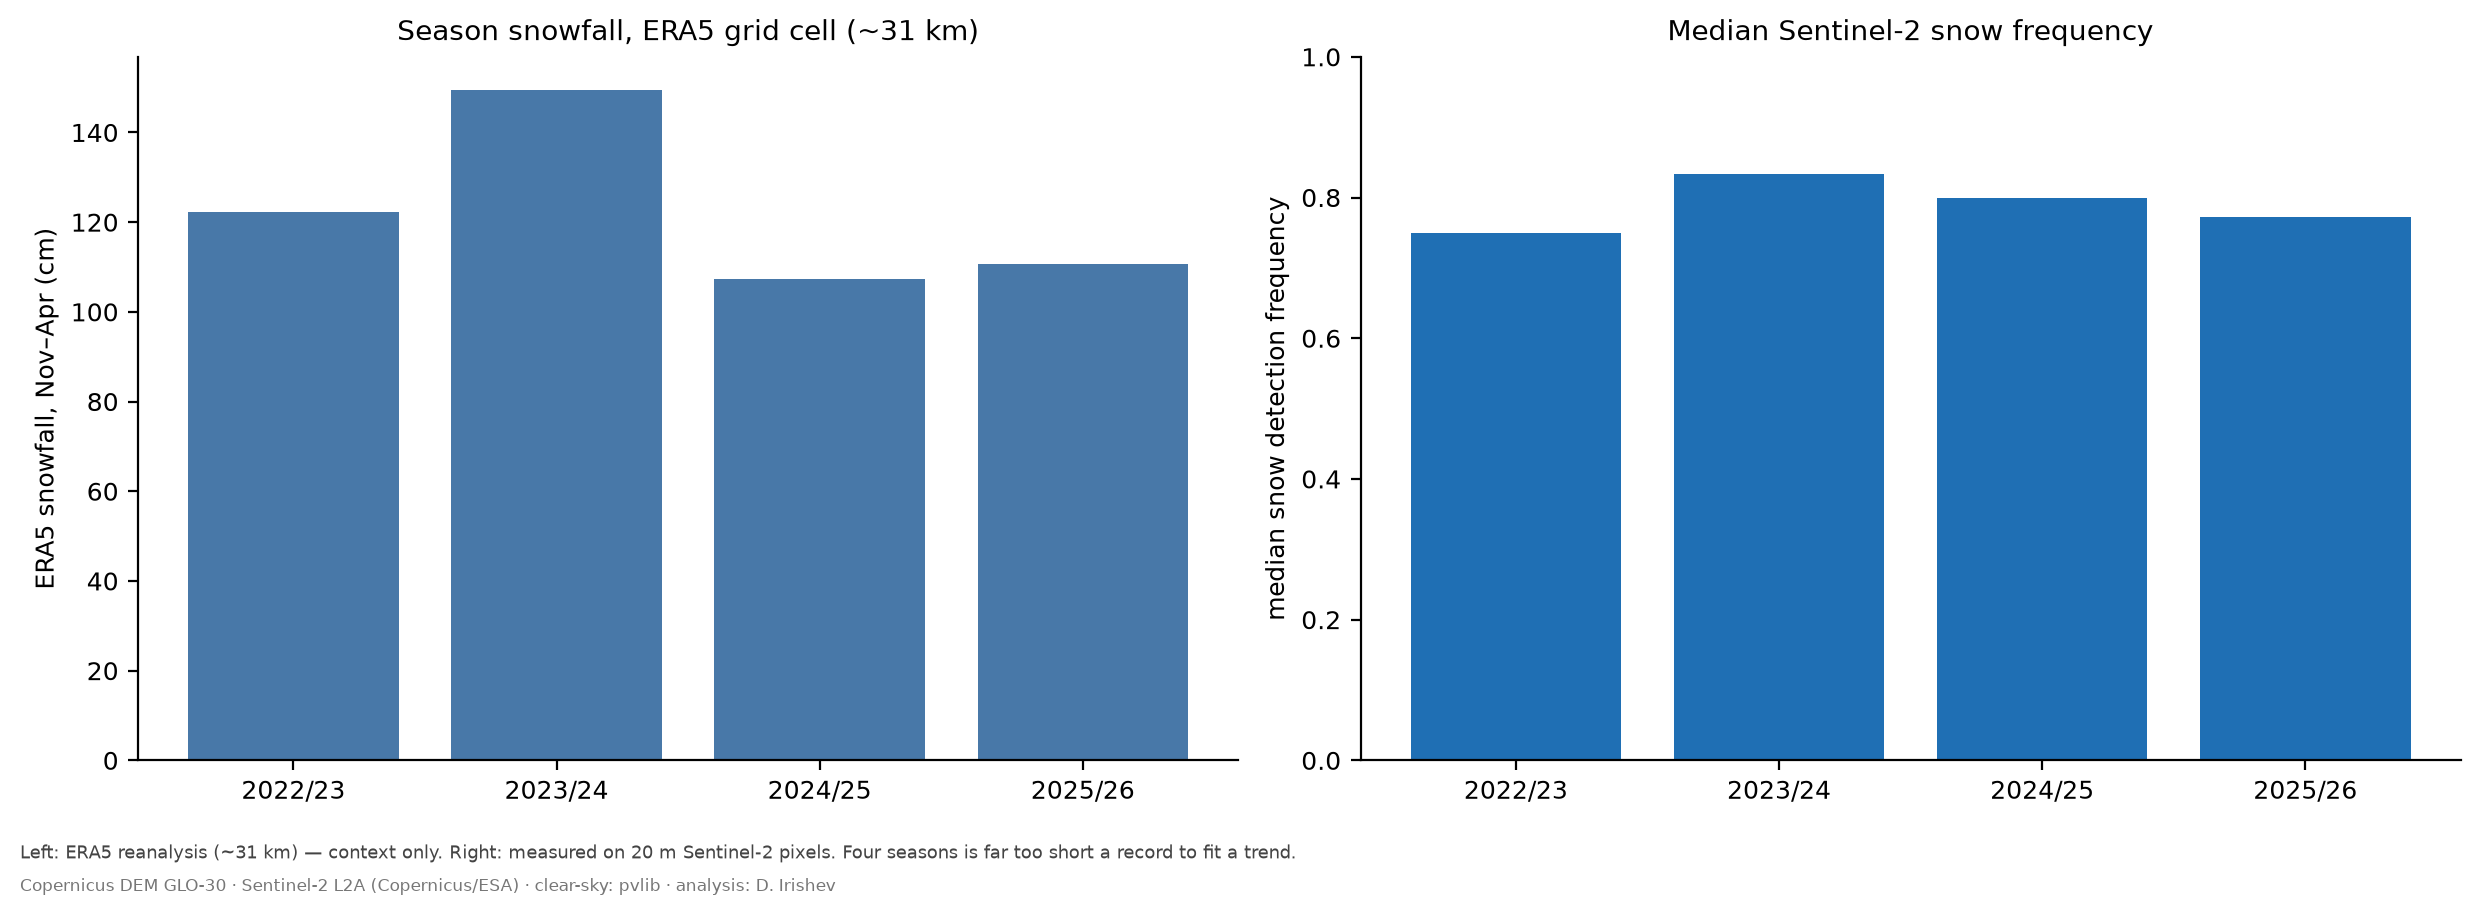

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/02_season_context.png')

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.2))
axes[0].bar(merged["season"], merged["snowfall_sum_cm"], color="#4878a8")
axes[0].set_ylabel("ERA5 snowfall, Nov–Apr (cm)")
axes[0].set_title("Season snowfall, ERA5 grid cell (~31 km)")
axes[1].bar(merged["season"], merged["median_snow_freq"], color="#1f6fb4")
axes[1].set_ylabel("median snow detection frequency")
axes[1].set_ylim(0, 1)
axes[1].set_title("Median Sentinel-2 snow frequency")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
save(fig, "02_season_context.png",
     "Left: ERA5 reanalysis (~31 km) — context only. Right: measured on 20 m Sentinel-2 "
     "pixels. Four seasons is far too short a record to fit a trend.")

## 8. GeoTIFF outputs

In [16]:
written = []
for s in SEASONS:
    r_ = season_freq[s]
    written.append(write_geotiff(
        OUT_TIF / f"snow_frequency_{s}.tif", r_["frequency"], S2_GRID, nodata=-9999,
        description=f"snow detection frequency, season {s}",
        n_dates=str(r_["n_dates"]), coverage=str(round(r_["coverage"], 4))))
    written.append(write_geotiff(
        OUT_TIF / f"valid_observations_{s}.tif", r_["n_valid"].astype("float32"),
        S2_GRID, nodata=-9999, description=f"usable observations per pixel, season {s}"))
    m = melt[s]
    written.append(write_geotiff(
        OUT_TIF / f"meltout_mid_day_{s}.tif", m["meltout_mid_day"], S2_GRID, nodata=-9999,
        description=f"snow disappearance midpoint, days after {m['origin']}",
        origin=m["origin"]))
    written.append(write_geotiff(
        OUT_TIF / f"meltout_interval_width_days_{s}.tif", m["interval_width_days"],
        S2_GRID, nodata=-9999, description="width of the bracketing interval, days"))

written.append(write_geotiff(OUT_TIF / "snow_frequency_4season.tif", four["frequency"],
                             S2_GRID, nodata=-9999,
                             description="snow detection frequency, 4 seasons, equal weight",
                             n_dates=str(four["n_dates"]),
                             min_seasons=str(MIN_SEASONS_MULTIYEAR)))
written.append(write_geotiff(OUT_TIF / "valid_observations_4season.tif",
                             four["n_valid"].astype("float32"), S2_GRID, nodata=-9999,
                             description="usable observations per pixel, 4 seasons"))
written.append(write_geotiff(OUT_TIF / "seasons_with_data_4season.tif",
                             four["n_seasons"].astype("float32"), S2_GRID, nodata=-9999,
                             description="number of seasons contributing to the pixel"))

snow_meta = {
    "run_date": RUN_DATE,
    "grid": {"crs": S2_GRID.crs, "res_m": S2_GRID.res, "shape": list(S2_GRID.shape)},
    "stac": {"url": STAC_URL, "collection": STAC_COLLECTION, "tile": MGRS_TILE,
             "max_cloud_pct": MAX_CLOUD_PCT, "fallback_used": False},
    "scenes": int(len(manifest)), "unique_dates": len(days),
    "historical_dates": len(hist), "current_season_dates": len(cur),
    "rule": {"ndsi_gt": NDSI_THRESHOLD, "nir_gt": NIR_THRESHOLD,
             "min_valid_obs": MIN_VALID_OBS,
             "min_seasons_multiyear": MIN_SEASONS_MULTIYEAR},
    "seasons": {k: list(v) for k, v in SEASONS.items()},
    "coverage": cov.to_dict(orient="records"),
}
json.dump(snow_meta, open(OUT_TIF / "snow_metadata.json", "w"), indent=1)
print(f"{len(written)} GeoTIFFs written")
for p in written:
    print(f"  {p.name}")

19 GeoTIFFs written
  snow_frequency_2022_23.tif
  valid_observations_2022_23.tif
  meltout_mid_day_2022_23.tif
  meltout_interval_width_days_2022_23.tif
  snow_frequency_2023_24.tif
  valid_observations_2023_24.tif
  meltout_mid_day_2023_24.tif
  meltout_interval_width_days_2023_24.tif
  snow_frequency_2024_25.tif
  valid_observations_2024_25.tif
  meltout_mid_day_2024_25.tif
  meltout_interval_width_days_2024_25.tif
  snow_frequency_2025_26.tif
  valid_observations_2025_26.tif
  meltout_mid_day_2025_26.tif
  meltout_interval_width_days_2025_26.tif
  snow_frequency_4season.tif
  valid_observations_4season.tif
  seasons_with_data_4season.tif
